# Segmentação de uma pluma de fumaça com o SAM (Segment Anything Model)

**Objetivo:** segmentar uma pluma de fumaça em uma imagem usando o SAM, avaliar o resultado e melhorar o código, os prompts e a apresentação da máscara.

**Etapas**
1. Preparação (instalação, modelo e imagem)
2. Segmentação automática, sem prompts
3. Três configurações de prompt (caixa; pontos positivos; caixa com pontos positivos e negativos), com imagem original, máscara binária e máscara sobreposta lado a lado
4. Melhorias: pós-processamento, refinamento iterativo e realce de contraste
5. Melhorias adicionais (CLAHE)
7. Máscara final e exportação
8. Análise crítica dos resultados

## 1. Preparação

In [1]:
!pip -q install git+https://github.com/facebookresearch/segment-anything.git opencv-python-headless matplotlib pandas scipy
!wget -q -nc https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

  Preparing metadata (setup.py) ... done


In [2]:
import numpy as np, cv2, torch, pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from segment_anything import sam_model_registry, SamPredictor, SamAutomaticMaskGenerator

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

MODEL_TYPE = "vit_b"   # modelo leve (vit_b)
CHECKPOINT = "sam_vit_b_01ec64.pth"
sam = sam_model_registry[MODEL_TYPE](checkpoint=CHECKPOINT).to(device)
predictor = SamPredictor(sam)

Dispositivo: cuda


### Carregamento da imagem
A imagem `pluma.png` é lida do repositório do GitHub. Caso não esteja disponível, é feito o upload manual do arquivo.

In [3]:
import os
from google.colab import files
IMG_URL = "https://raw.githubusercontent.com/Gian3010/Detec-o-e-segmenta-o-de-uma-pluma-com-SAM/main/pluma.png"
if not os.path.exists("pluma.png"):
    os.system(f"wget -q -O pluma.png {IMG_URL}")
if os.path.exists("pluma.png") and os.path.getsize("pluma.png") > 1000:
    path = "pluma.png"
else:
    up = files.upload()
    path = list(up.keys())[0]

image = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
MAX_SIDE = 1600
h, w = image.shape[:2]
if max(h, w) > MAX_SIDE:
    s = MAX_SIDE / max(h, w)
    image = cv2.resize(image, (int(w*s), int(h*s)), interpolation=cv2.INTER_AREA)
print("Tamanho da imagem (altura, largura):", image.shape[:2])

Tamanho da imagem (altura, largura): (541, 810)


### Grade de coordenadas
A grade ajuda a localizar a pluma e a definir a caixa e os pontos de prompt (coordenadas em pixels: x na horizontal, y na vertical).

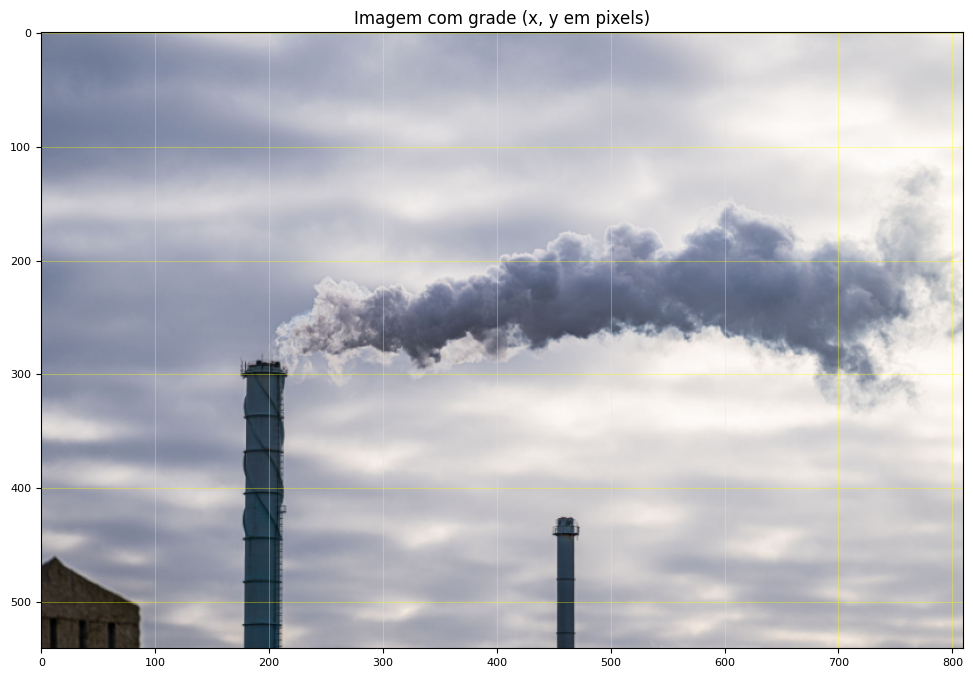

In [4]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)
ax.set_xticks(range(0, image.shape[1], 100))
ax.set_yticks(range(0, image.shape[0], 100))
ax.grid(color="yellow", alpha=0.4, linewidth=0.6)
ax.tick_params(labelsize=8)
ax.set_title("Imagem com grade (x, y em pixels)")
plt.show()

## 2. Funções auxiliares de visualização

In [5]:
def overlay(img, mask, color=(255, 0, 0), alpha=0.5, contour=True):
    out = img.copy().astype(np.float32)
    c = np.array(color, dtype=np.float32)
    out[mask] = (1 - alpha) * out[mask] + alpha * c
    out = out.astype(np.uint8)
    if contour:
        cs, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cs, -1, (255, 255, 0), 2)
    return out

def draw_prompts(ax, box=None, pos=None, neg=None):
    if box is not None:
        x0, y0, x1, y1 = box
        ax.add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0, fill=False, edgecolor="lime", linewidth=2))
    if pos is not None and len(pos):
        p = np.array(pos); ax.scatter(p[:,0], p[:,1], c="lime", marker="*", s=250, edgecolor="white", linewidth=1.2)
    if neg is not None and len(neg):
        n = np.array(neg); ax.scatter(n[:,0], n[:,1], c="red", marker="X", s=180, edgecolor="white", linewidth=1.2)

def side_by_side(img, mask, title="", box=None, pos=None, neg=None, score=None):
    fig, axs = plt.subplots(1, 3, figsize=(18, 6))
    axs[0].imshow(img); draw_prompts(axs[0], box, pos, neg)
    axs[0].set_title("Imagem original (+ prompts)")
    axs[1].imshow(mask, cmap="gray"); axs[1].set_title("Máscara binária")
    axs[2].imshow(overlay(img, mask)); axs[2].set_title("Máscara sobreposta")
    for a in axs: a.axis("off")
    t = title + (f"  |  score SAM = {score:.3f}" if score is not None else "")
    fig.suptitle(t + f"  |  área = {100*mask.mean():.1f}% da imagem", fontsize=14)
    plt.tight_layout(); plt.show()

def iou(a, b):
    inter = np.logical_and(a, b).sum(); union = np.logical_or(a, b).sum()
    return inter / union if union else 0.0

## 3. Segmentação automática (sem prompts)

O gerador automático de máscaras segmenta todos os objetos que encontra na imagem (céu, nuvens, chaminés, prédio e fumaça). Isso mostra a necessidade de usar prompts para indicar qual objeto interessa.

Máscaras automáticas encontradas: 14


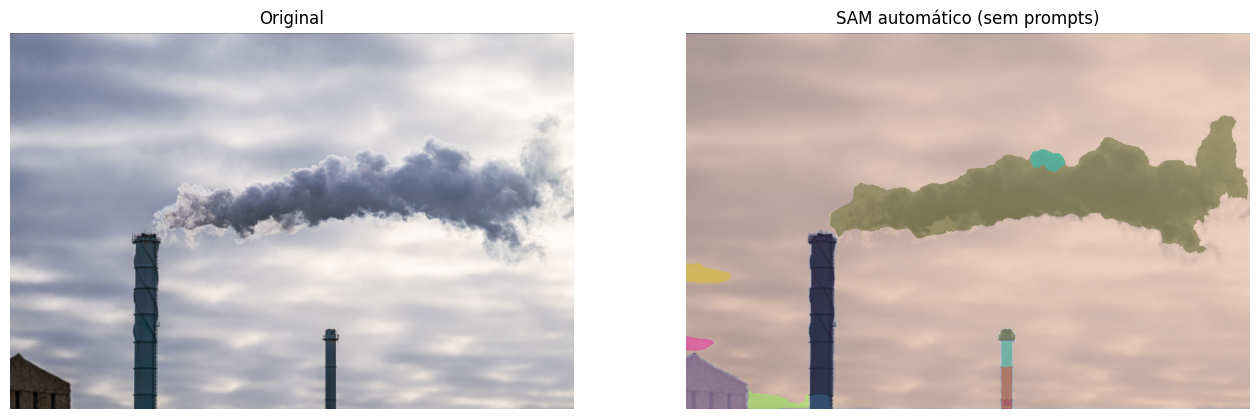

In [6]:
mask_generator = SamAutomaticMaskGenerator(sam, points_per_side=24, pred_iou_thresh=0.86, stability_score_thresh=0.9, min_mask_region_area=500)
auto_masks = mask_generator.generate(image)
auto_masks = sorted(auto_masks, key=lambda m: m["area"], reverse=True)
print("Máscaras automáticas encontradas:", len(auto_masks))

canvas = image.astype(np.float32).copy()
rng = np.random.default_rng(0)
for m in auto_masks:
    canvas[m["segmentation"]] = 0.45*canvas[m["segmentation"]] + 0.55*rng.integers(40, 255, 3)
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
axs[0].imshow(image); axs[0].set_title("Original")
axs[1].imshow(canvas.astype(np.uint8)); axs[1].set_title("SAM automático (sem prompts)")
for a in axs: a.axis("off")
plt.show()

## 4. Três configurações de prompt

- `BOX = [x0, y0, x1, y1]`: caixa delimitadora ao redor da pluma
- `POS`: pontos positivos (rótulo 1), dentro da fumaça: base, corpo e cauda
- `NEG`: pontos negativos (rótulo 0), em regiões que não são fumaça: céu, nuvens vizinhas e chaminés

As coordenadas foram definidas a partir da grade da imagem `pluma.png`.

In [7]:
# Coordenadas definidas como fração da imagem (largura W, altura H), calibradas para a foto das chaminés
# (pluma cinza saindo da chaminé alta, em direção à direita, sobre céu nublado).
H, W = image.shape[:2]
def P(fx, fy): return (int(fx*W), int(fy*H))

BOX = np.array([int(0.245*W), int(0.21*H), int(0.995*W), int(0.62*H)])      # [x0, y0, x1, y1] ao redor da pluma
POS = [P(0.41, 0.46), P(0.555, 0.415), P(0.74, 0.40), P(0.89, 0.445)]       # dentro da fumaça (base, corpo, cauda)
NEG = [P(0.12, 0.185), P(0.62, 0.13),                                       # céu/nuvens acima
       P(0.49, 0.61),                                                       # nuvem logo abaixo da pluma
       P(0.24, 0.78), P(0.568, 0.905),                                      # chaminés
       P(0.80, 0.795)]                                                      # céu/nuvens inferiores

configs = {
    "A) Somente caixa":                        dict(box=BOX,  pos=[],  neg=[]),
    "B) Somente pontos positivos":             dict(box=None, pos=POS, neg=[]),
    "C) Caixa + positivos + negativos":        dict(box=BOX,  pos=POS, neg=NEG),
}

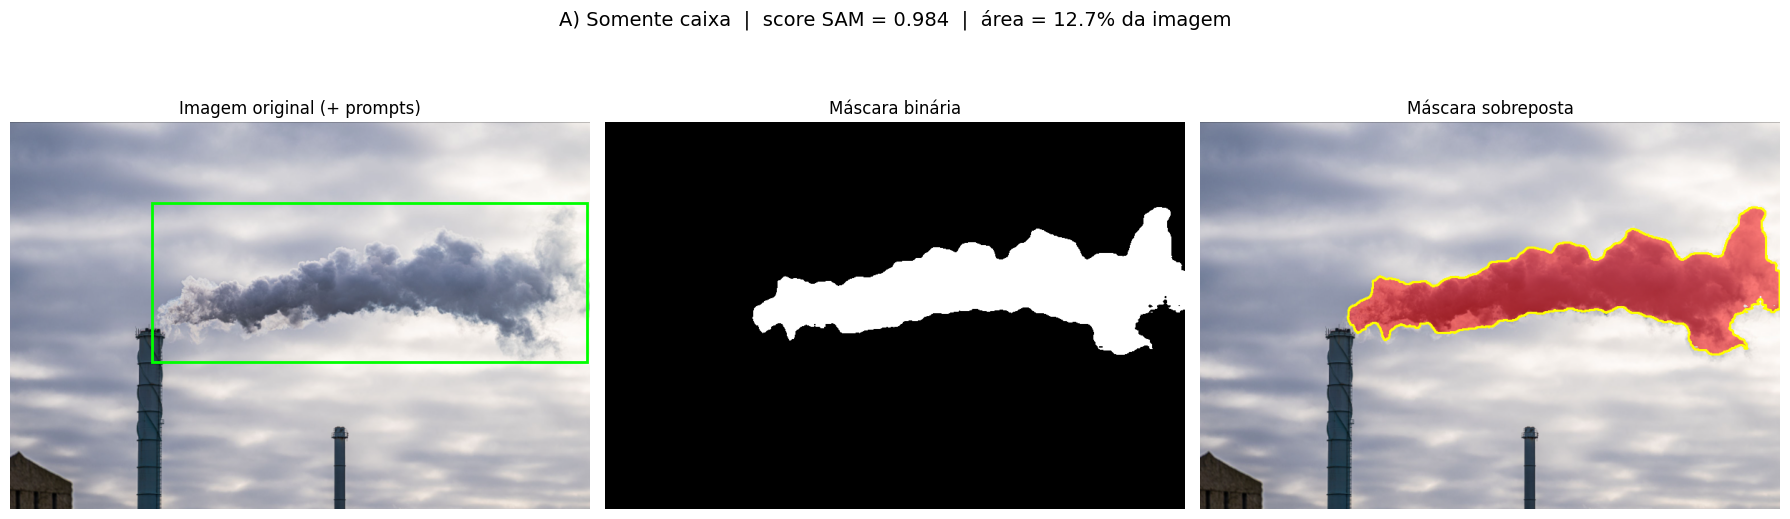

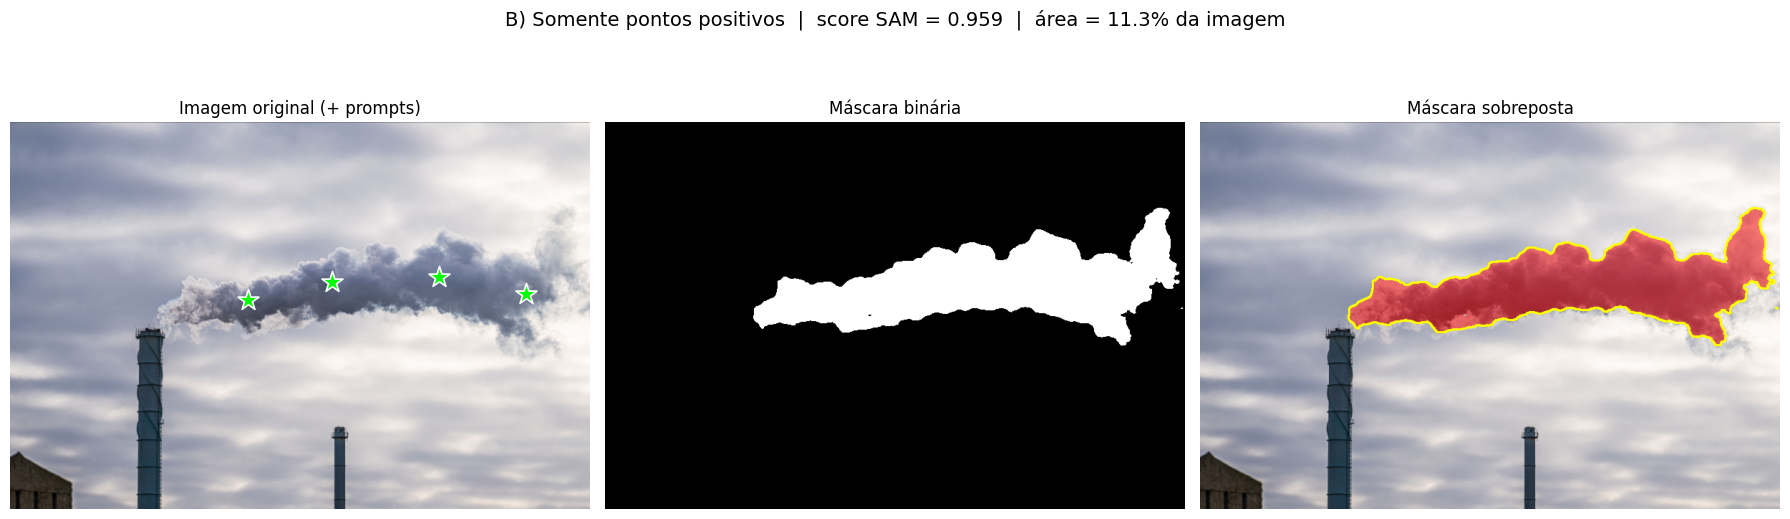

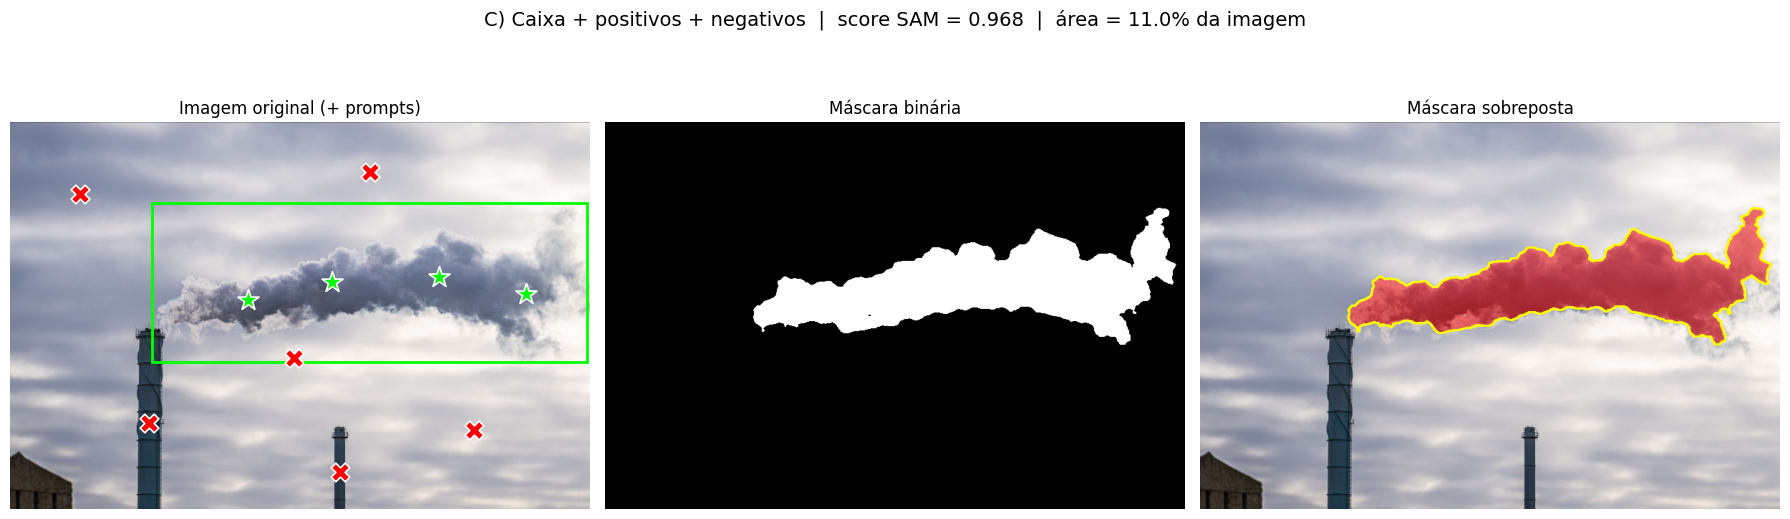

In [8]:
predictor.set_image(image)   # embedding da imagem calculado uma única vez

def run_sam(box=None, pos=(), neg=(), multimask=True, mask_input=None):
    pts = list(pos) + list(neg)
    coords = np.array(pts) if pts else None
    labels = np.array([1]*len(pos) + [0]*len(neg)) if pts else None
    masks, scores, logits = predictor.predict(
        point_coords=coords, point_labels=labels,
        box=None if box is None else np.array(box),
        mask_input=mask_input, multimask_output=multimask)
    return masks, scores, logits

def pick_mask(masks, scores, pos, neg, max_area=0.6):
    # escolhe a máscara mais coerente com os prompts: favorece pontos positivos dentro,
    # penaliza pontos negativos dentro e máscaras que cobrem quase toda a imagem
    best, best_val = 0, -1e9
    for i, m in enumerate(masks):
        hits_pos = sum(bool(m[y, x]) for x, y in pos)
        hits_neg = sum(bool(m[y, x]) for x, y in neg)
        val = hits_pos - 2*hits_neg + float(scores[i])
        if m.mean() > max_area: val -= 5
        if val > best_val: best, best_val = i, val
    return best

results = {}
for name, cfg in configs.items():
    masks, scores, logits = run_sam(cfg["box"], cfg["pos"], cfg["neg"])
    best = pick_mask(masks, scores, cfg["pos"], cfg["neg"])
    results[name] = dict(masks=masks, scores=scores, logits=logits, best=best, mask=masks[best], score=scores[best])
    side_by_side(image, masks[best], title=name, box=cfg["box"], pos=cfg["pos"], neg=cfg["neg"], score=scores[best])

#### Hipóteses de máscara do SAM em cada configuração
Para cada configuração, o SAM devolve três máscaras candidatas (subparte, parte e objeto inteiro). Aqui elas são comparadas para verificar se a de maior score é a mais adequada para a fumaça.

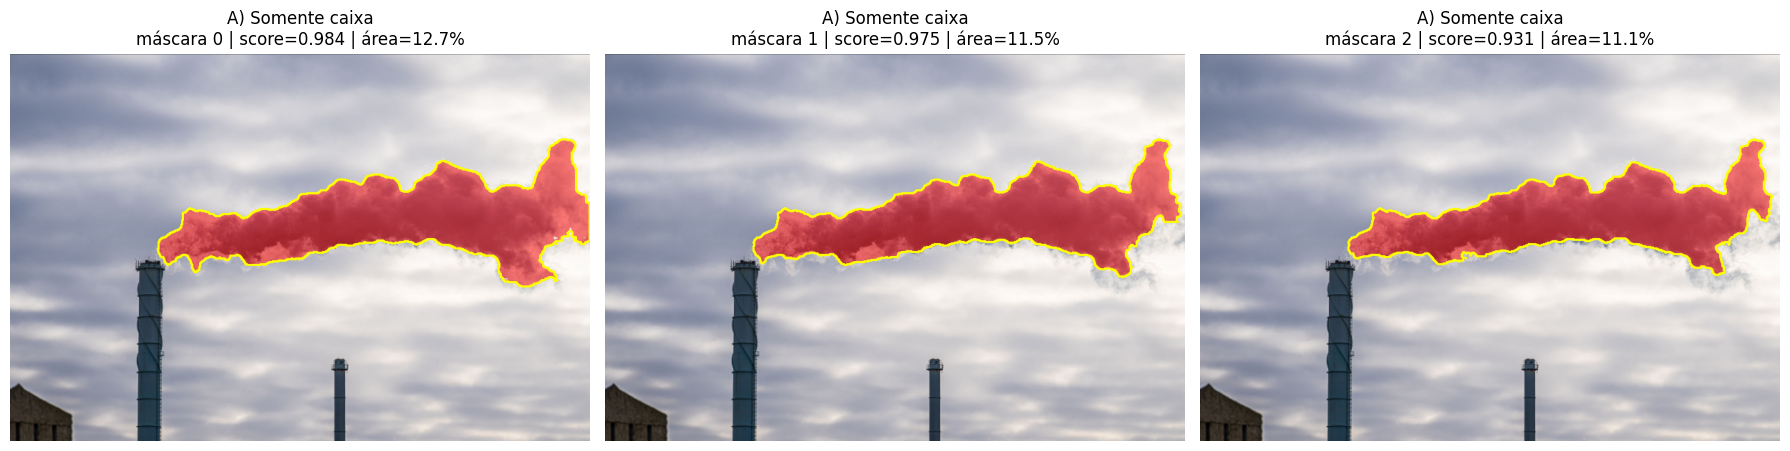

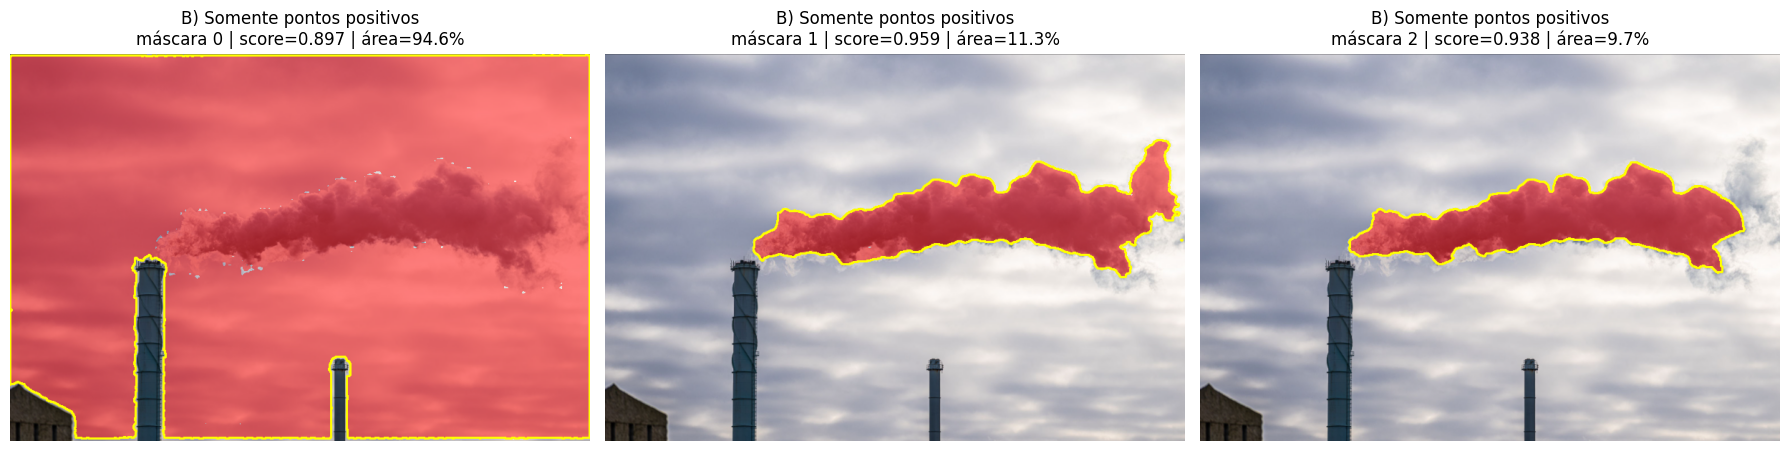

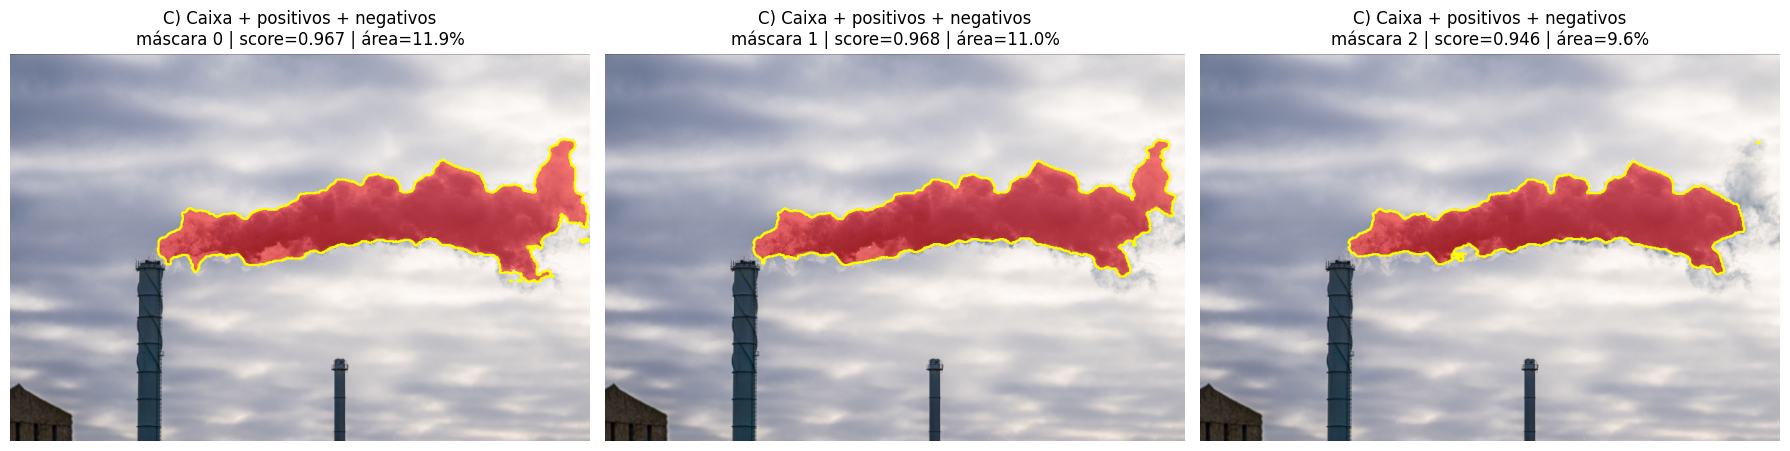

In [9]:
for name, r in results.items():
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    for i in range(3):
        axs[i].imshow(overlay(image, r["masks"][i])); axs[i].axis("off")
        axs[i].set_title(f"{name}\nmáscara {i} | score={r['scores'][i]:.3f} | área={100*r['masks'][i].mean():.1f}%")
    plt.tight_layout(); plt.show()

## 5. Melhorias

Problemas esperados: a máscara pode vazar para céu, nuvens ou prédios, ter ilhas isoladas e buracos internos, ou deixar de fora as bordas translúcidas da fumaça. Foram testadas três melhorias:

1. **Pós-processamento morfológico:** abertura e fechamento, preenchimento de buracos e manutenção apenas do componente conectado que contém os pontos positivos.
2. **Refinamento iterativo:** os logits da primeira predição são reenviados ao SAM como `mask_input`.
3. **Realce de contraste (CLAHE):** aumenta a diferença entre fumaça e fundo antes de calcular o embedding da imagem.

In [10]:
def postprocess(mask, pos_pts=(), open_k=5, close_k=15, min_area_frac=0.001):
    m = mask.astype(np.uint8)
    # 1) abertura remove pequenas ilhas/ruído; fechamento une partes da pluma
    k_open  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (open_k, open_k))
    k_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_k, close_k))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, k_open)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k_close)
    # 2) preencher buracos internos
    m = ndi.binary_fill_holes(m).astype(np.uint8)
    # 3) manter componentes que contêm pontos positivos (ou o maior, se não houver pontos)
    n, lab = cv2.connectedComponents(m)
    keep = np.zeros_like(m)
    ids = {lab[y, x] for (x, y) in pos_pts if 0 <= y < lab.shape[0] and 0 <= x < lab.shape[1] and lab[y, x] > 0}
    if not ids and n > 1:
        areas = [(lab == i).sum() for i in range(1, n)]
        ids = {1 + int(np.argmax(areas))}
    for i in ids: keep[lab == i] = 1
    if keep.sum() == 0:            # se o pós-processamento apagar tudo, mantém a máscara original
        return mask.astype(bool)
    return keep.astype(bool)

def refine_iterative(box, pos, neg, first_logits, fallback_mask, n_iter=2):
    # reenvia o logit (256x256) como entrada de máscara; se o refinamento colapsar, mantém a máscara anterior
    logit = first_logits
    out_m, out_s = fallback_mask, 0.0
    for _ in range(n_iter):
        masks, scores, logits = run_sam(box, pos, neg, multimask=False, mask_input=logit[None, :, :])
        m = masks[0]
        if m.sum() < 0.3 * fallback_mask.sum():   # máscara quase vazia: descarta
            break
        out_m, out_s, logit = m, scores[0], logits[0]
    return out_m, out_s

def enhance_contrast(img, clip=3.0, tile=8):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2RGB)

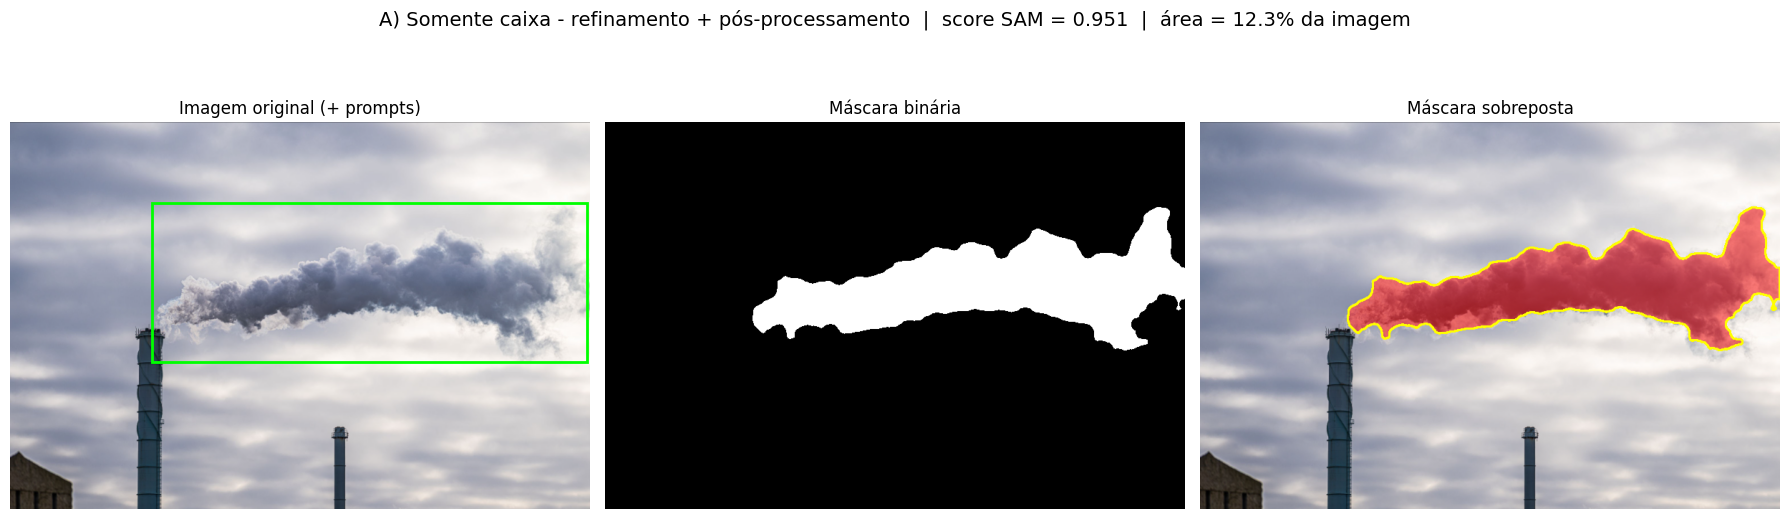

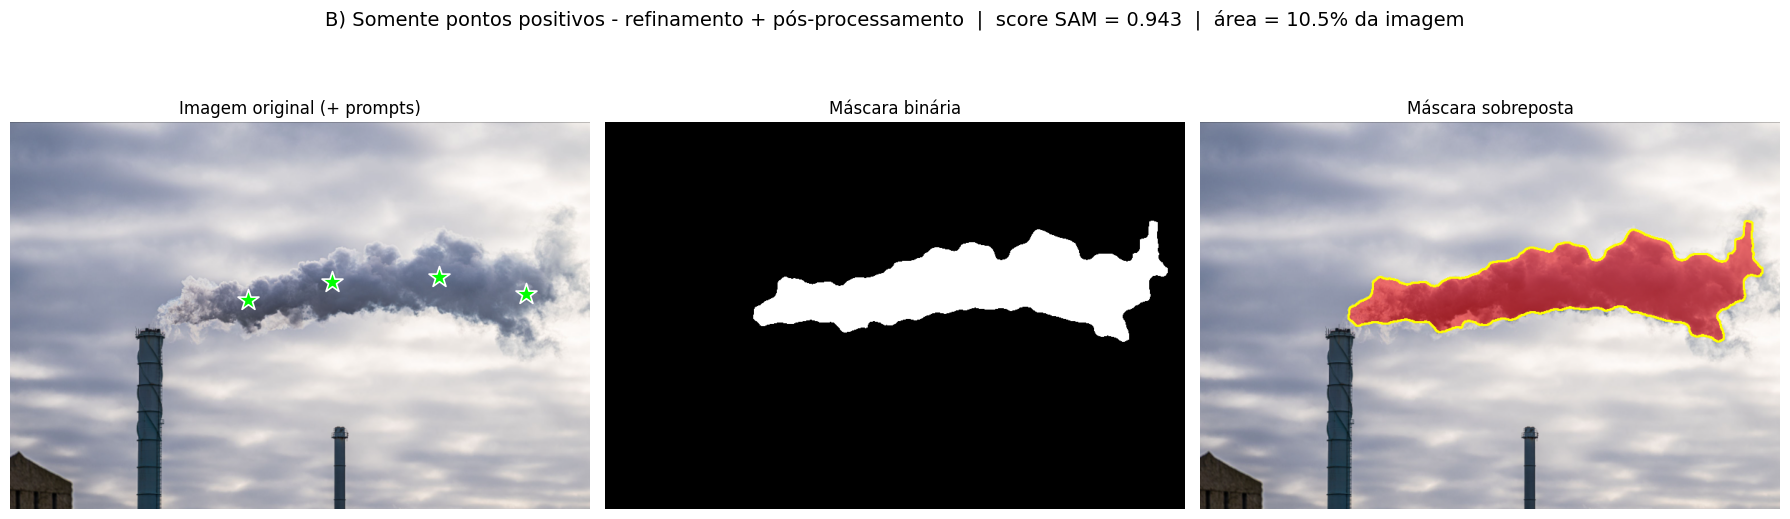

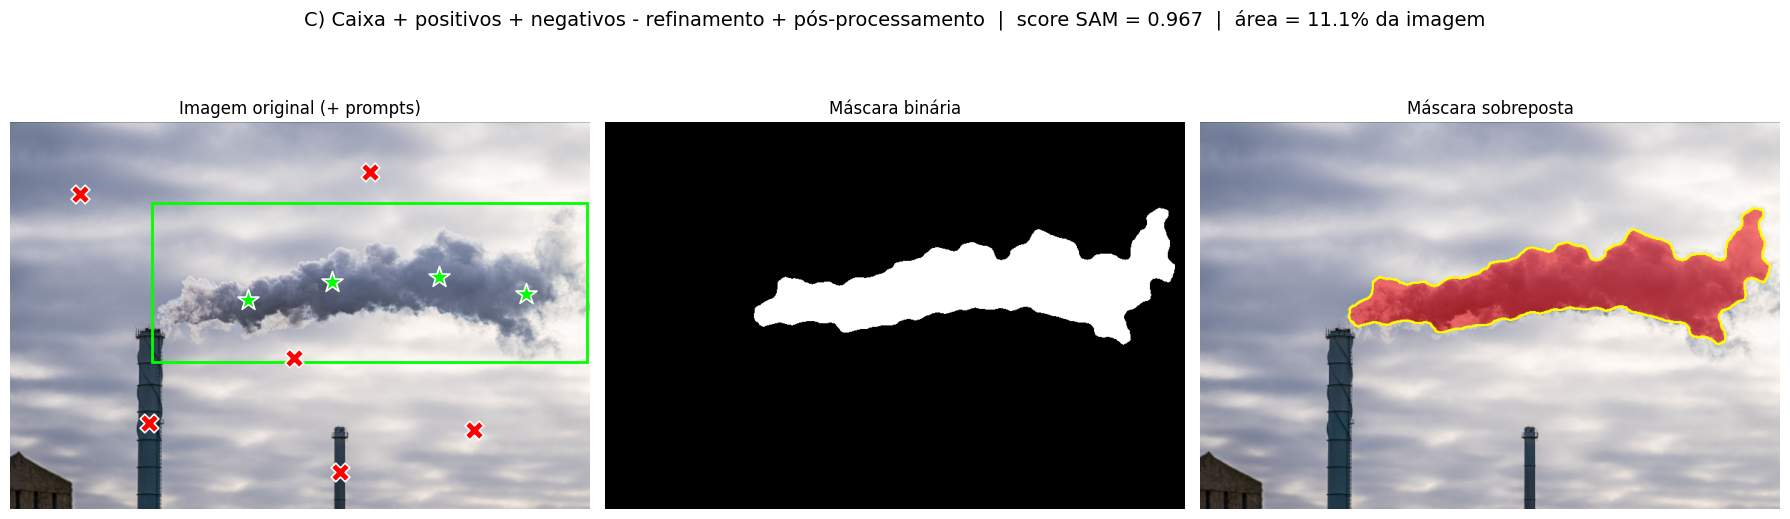

In [11]:
improved = {}
for name, cfg in configs.items():
    r = results[name]
    # (1) pós-processamento
    m_post = postprocess(r["mask"], cfg["pos"])
    # (2) refinamento iterativo a partir do melhor logit
    m_ref, s_ref = refine_iterative(cfg["box"], cfg["pos"], cfg["neg"], r["logits"][r["best"]], r["mask"])
    m_ref_post = postprocess(m_ref, cfg["pos"])
    improved[name] = dict(post=m_post, refined=m_ref, refined_post=m_ref_post, score_ref=s_ref)
    side_by_side(image, m_ref_post, title=f"{name} - refinamento + pós-processamento",
                 box=cfg["box"], pos=cfg["pos"], neg=cfg["neg"], score=s_ref)

### Pré-processamento de contraste (CLAHE) na melhor configuração (C)

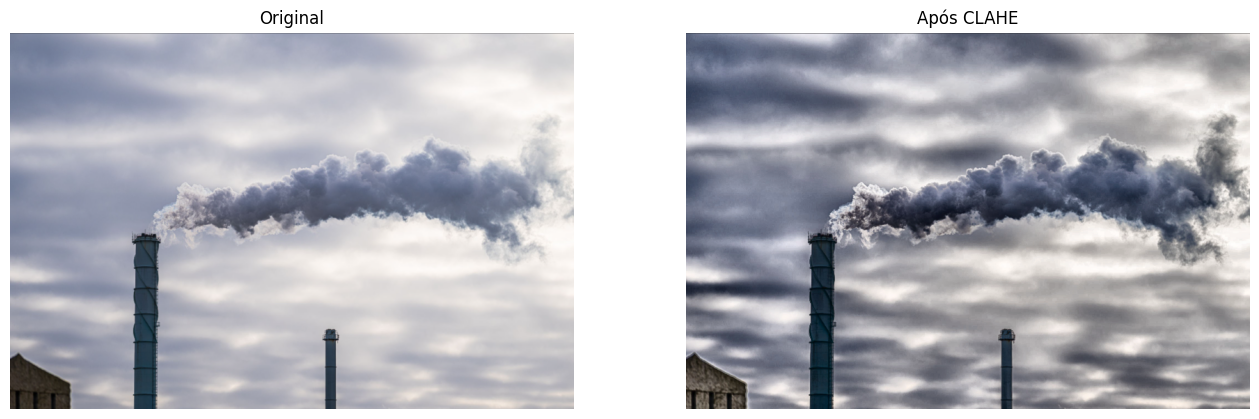

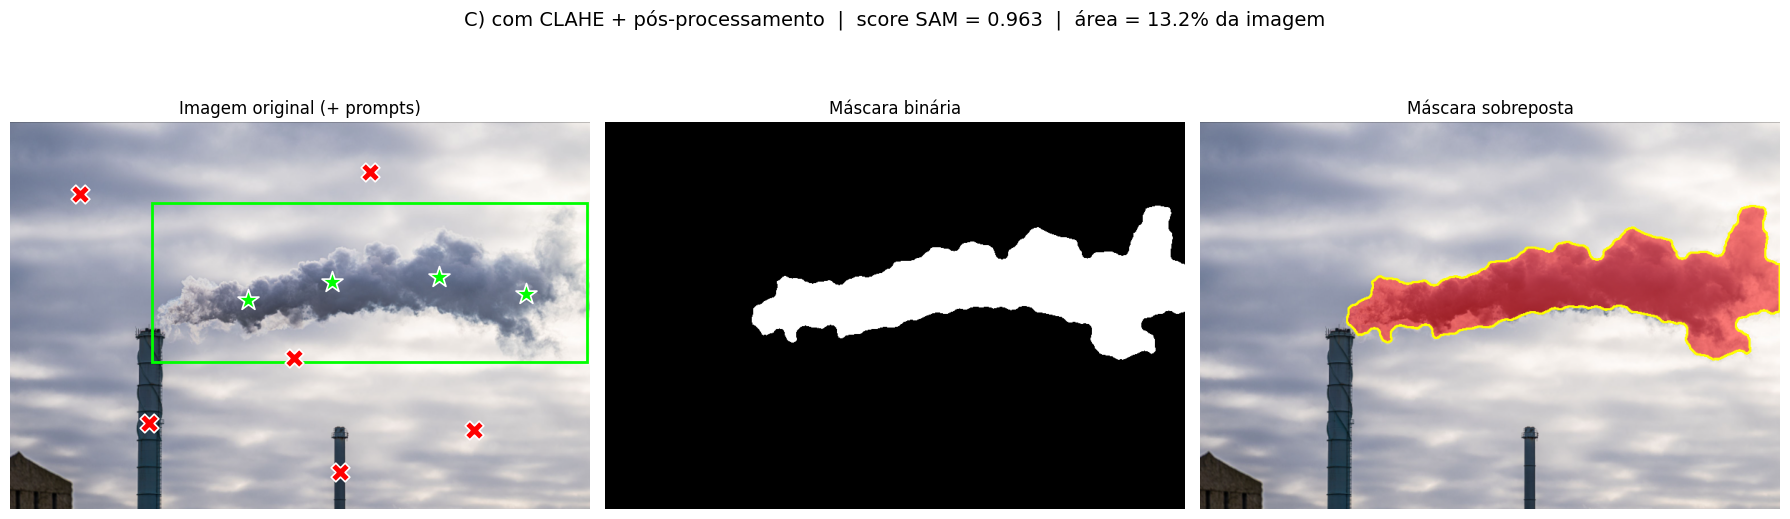

In [12]:
image_clahe = enhance_contrast(image)
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
axs[0].imshow(image); axs[0].set_title("Original")
axs[1].imshow(image_clahe); axs[1].set_title("Após CLAHE")
for a in axs: a.axis("off")
plt.show()

cfg = configs["C) Caixa + positivos + negativos"]
predictor.set_image(image_clahe)
masks_c, scores_c, logits_c = run_sam(cfg["box"], cfg["pos"], cfg["neg"])
b = pick_mask(masks_c, scores_c, cfg["pos"], cfg["neg"])
mask_clahe = postprocess(masks_c[b], cfg["pos"])
side_by_side(image, mask_clahe, title="C) com CLAHE + pós-processamento",
             box=cfg["box"], pos=cfg["pos"], neg=cfg["neg"], score=scores_c[b])
predictor.set_image(image)  # volta ao embedding da imagem original

## 6. Métricas comparativas
Como não há máscara de referência, as configurações são comparadas entre si (IoU), além da área e do score do SAM. Se houver uma máscara de referência manual, o caminho pode ser informado em `GT_PATH`.

In [13]:
GT_PATH = None   # caminho da máscara de referência (branco = fumaça), se existir

rows = []
ref_C = results["C) Caixa + positivos + negativos"]["mask"]
gt = None
if GT_PATH:
    gt = cv2.resize(cv2.imread(GT_PATH, 0), (image.shape[1], image.shape[0]), interpolation=cv2.INTER_NEAREST) > 127

for name in configs:
    r, im = results[name], improved[name]
    for tag, m in [("SAM bruto", r["mask"]), ("pós-proc.", im["post"]), ("refinado+pós", im["refined_post"])]:
        row = {"Configuração": name, "Versão": tag, "Área (%)": round(100*m.mean(), 2),
               "IoU vs C bruto": round(iou(m, ref_C), 3)}
        if gt is not None: row["IoU vs referência"] = round(iou(m, gt), 3)
        rows.append(row)
rows.append({"Configuração": "C) + CLAHE", "Versão": "CLAHE+pós", "Área (%)": round(100*mask_clahe.mean(), 2),
             "IoU vs C bruto": round(iou(mask_clahe, ref_C), 3),
             **({"IoU vs referência": round(iou(mask_clahe, gt), 3)} if gt is not None else {})})
df = pd.DataFrame(rows)
display(df)

,Configuração,Versão,Área (%),IoU vs C bruto
0,A) Somente caixa,SAM bruto,12.65,0.870
1,A) Somente caixa,pós-proc.,12.70,0.867
2,A) Somente caixa,refinado+pós,12.32,0.893
3,B) Somente pontos positivos,SAM bruto,11.29,0.967
4,B) Somente pontos positivos,pós-proc.,11.36,0.962
5,B) Somente pontos positivos,refinado+pós,10.51,0.937
6,C) Caixa + positivos + negativos,SAM bruto,11.01,1.000
7,C) Caixa + positivos + negativos,pós-proc.,11.08,0.991
8,C) Caixa + positivos + negativos,refinado+pós,11.08,0.973
9,C) + CLAHE,CLAHE+pós,13.18,0.830


## 7. Máscara final e exportação

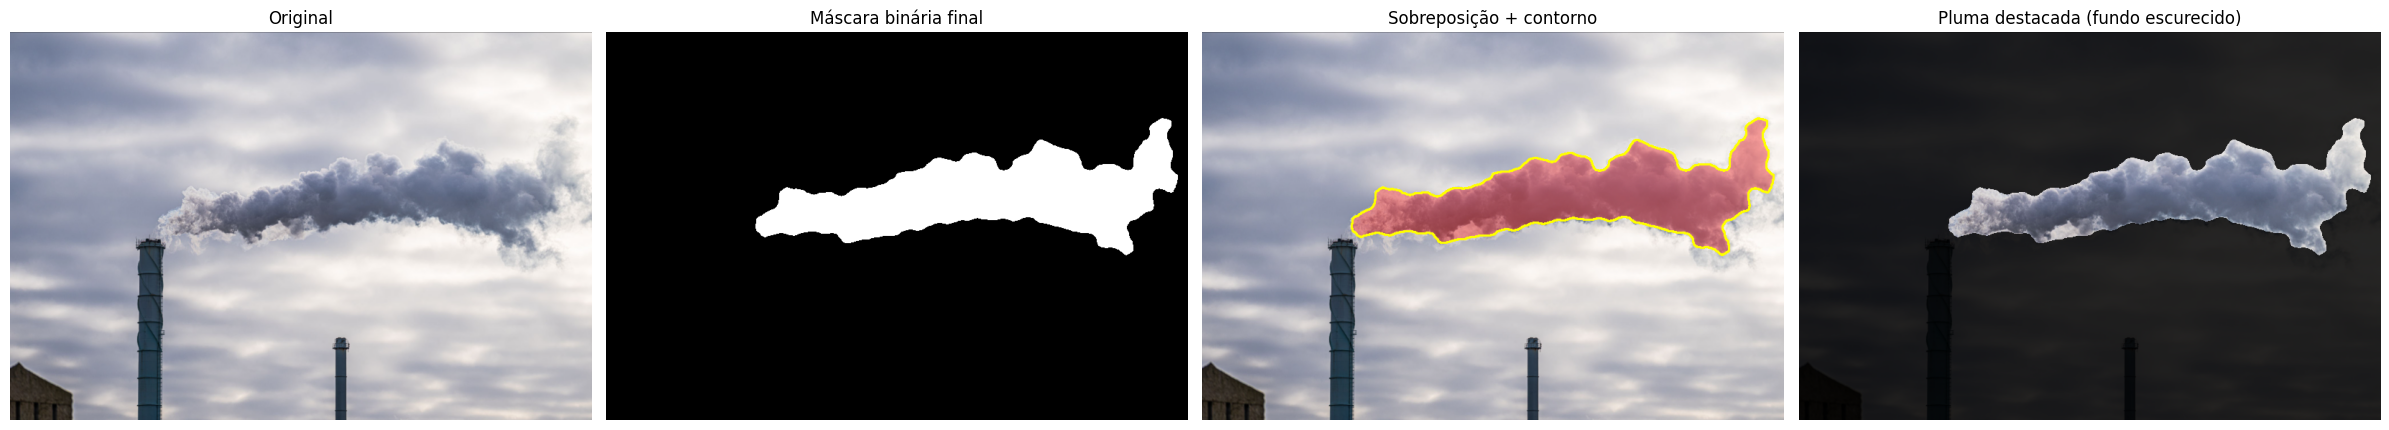

Salvos: mascara_final.png e resultado_final.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
final_mask = improved["C) Caixa + positivos + negativos"]["refined_post"]   # máscara final: configuração C com refinamento e pós-processamento
cfg = configs["C) Caixa + positivos + negativos"]

# apresentação: máscara binária, sobreposição com contorno e pluma destacada
fig, axs = plt.subplots(1, 4, figsize=(24, 6))
axs[0].imshow(image); axs[0].set_title("Original")
axs[1].imshow(final_mask, cmap="gray"); axs[1].set_title("Máscara binária final")
axs[2].imshow(overlay(image, final_mask, color=(255, 60, 60), alpha=0.45)); axs[2].set_title("Sobreposição + contorno")
cut = image.copy(); cut[~final_mask] = (cut[~final_mask] * 0.15).astype(np.uint8)
axs[3].imshow(cut); axs[3].set_title("Pluma destacada (fundo escurecido)")
for a in axs: a.axis("off")
plt.tight_layout(); plt.savefig("resultado_final.png", dpi=150); plt.show()

cv2.imwrite("mascara_final.png", final_mask.astype(np.uint8) * 255)
print("Salvos: mascara_final.png e resultado_final.png")
files.download("mascara_final.png"); files.download("resultado_final.png")

## 8. Análise crítica

**Observação sobre as métricas.** Não há máscara de referência (`GT_PATH = None`). Os valores de IoU abaixo comparam as versões entre si (referência: configuração C bruta) e **não** medem a precisão real. O "score" é a confiança estimada pelo próprio SAM, não uma métrica de acerto. A avaliação da qualidade da borda foi feita por inspeção visual das máscaras sobrepostas.

### 8.1 Avaliação da máscara inicial do SAM

**Resultado sem prompts (baseline automático).** O gerador automático encontrou 14 máscaras. Uma delas já corresponde à pluma inteira, mas ela aparece misturada às demais: o céu nublado como um bloco único de fundo, as duas chaminés (a menor dividida em partes), o prédio no canto e pequenos fragmentos de nuvem. Sem prompts, portanto, o SAM não sabe qual segmento é "a fumaça". A escolha da máscara certa ainda depende de uma intervenção humana, e é isso que justifica o uso de prompts.

**Resultado com prompts (configurações A, B e C).** As três configurações produziram uma máscara coerente com a pluma:

- **A máscara cobre a pluma?** Sim. O corpo escuro e bem definido da pluma, desde a saída da chaminé até a cauda à direita, foi coberto por todas as configurações (área de 11,0% a 12,7% da imagem, score do SAM entre 0,959 e 0,984).
- **Inclui regiões que não pertencem a ela?** Praticamente não. Não houve vazamento para o céu, para as nuvens vizinhas, para as chaminés nem para o prédio. Na configuração A (somente caixa), a máscara termina exatamente na borda direita da caixa, ou seja, o limite da caixa recortou a cauda em vez de a borda real da fumaça.
- **Deixa partes da fumaça de fora?** Sim, as partes mais difusas. O halo translúcido sob a pluma e as bordas finas do trecho final da cauda (fumaça clara, quase da cor do céu) ficaram de fora em todas as configurações. A máscara acompanha o "núcleo" opaco da fumaça, e não a transição gradual até o ar limpo.

### 8.2 Comparação das três configurações de prompt

| Configuração | Área (%) bruta | IoU vs C | Score SAM | Observação |
|---|---|---|---|---|
| A) Somente caixa | 12,65 | 0,870 | 0,984 | Maior área e o menor IoU em relação a C. A máscara é cortada pelo limite direito da caixa |
| B) Somente pontos positivos | 11,29 | 0,967 | 0,959 | Resultado quase idêntico ao de C; os pontos no corpo escuro da pluma bastaram |
| C) Caixa + positivos + negativos | 11,01 | 1,000 (ref.) | 0,968 | Máscara mais "enxuta"; combina o limite espacial da caixa com a exclusão explícita de céu, nuvens e chaminés |

- Neste caso, **os pontos negativos trouxeram pouco ganho** (IoU de B vs C = 0,967). O contraste entre a fumaça escura e o céu claro e o uso de quatro pontos bem distribuídos já bastavam para o SAM isolar a pluma. Os negativos funcionam, sobretudo, como seguro contra vazamento para nuvens.
- A **caixa** limita a região de busca, mas pode truncar o objeto se estiver apertada, como ocorreu na cauda da configuração A. Combinada com pontos (C), o problema desaparece.
- O **score do SAM não acompanha a qualidade percebida**: A teve o maior score (0,984), mas foi a configuração com o recorte artificial na borda da caixa. Por isso o score deve ser usado com cautela como critério de escolha.

### 8.3 Características da imagem que dificultaram a segmentação

- **Iluminação.** A cena é em contraluz suave, com o céu claro atrás da pluma. O núcleo da fumaça fica escuro e bem contrastado, o que ajudou o SAM. Já a cauda e o halo da pluma ficam iluminados pelo fundo e perdem opacidade, aproximando-se da luminosidade do céu. Foi essa a parte que a máscara não capturou.
- **Contraste.** O contraste entre fumaça e fundo é alto no corpo da pluma, mas cai de forma gradual em direção às bordas. Como o SAM se apoia em bordas, a fronteira é nítida onde há contraste e incerta onde a fumaça se dilui. Qualquer máscara binária é, nesse caso, uma simplificação, porque a fumaça não tem um limite bem definido.
- **Semelhança entre fumaça e nuvens.** O céu é uma camada de nuvens cinza-azuladas com textura parecida com a da fumaça. Esse era o principal risco de vazamento. Na prática, a diferença de tom e de opacidade entre o núcleo da pluma e as nuvens foi suficiente para o SAM separá-los, mas a semelhança é a razão pela qual o halo difuso (cor e textura próximas às das nuvens) foi excluído.
- **Outros elementos.** As chaminés e o prédio têm bordas nítidas e poderiam ser confundidos com a pluma por estarem próximos da base. Nenhum deles entrou na máscara. A chaminé alta toca a base da pluma, mas o SAM manteve a separação.

### 8.4 Efeito das melhorias

| Versão | A | B | C |
|---|---|---|---|
| SAM bruto (área %) | 12,65 | 11,29 | 11,01 |
| Pós-processamento (área %) | 12,70 | 11,36 | 11,08 |
| Refinamento + pós (área %) | 12,32 | 10,51 | 11,08 |

- **Pós-processamento morfológico** (abertura, fechamento, preenchimento de buracos e componente conectado): alterou pouco a máscara (variação de até 0,07 p.p. na área; IoU de 0,99 vs a versão bruta de C). Isso indica que as máscaras do SAM já eram limpas, sem ilhas nem buracos relevantes. A melhoria é útil como garantia, mas o impacto aqui foi pequeno.
- **Refinamento iterativo** (reenvio do logit como `mask_input`): em C praticamente não mudou a área (11,08%); em B reduziu a máscara (11,29% → 10,51%) e em A reduziu um pouco (12,65% → 12,32%). Isso sugere que o refinamento tende a "apertar" a máscara em torno do núcleo da fumaça, o que pode ser bom contra vazamentos, mas reforça a perda das bordas translúcidas.
- **Realce de contraste (CLAHE):** foi a única mudança que **ampliou** a máscara (13,18%, IoU de 0,830 vs C). Ao realçar o contraste local, o SAM passou a incluir mais da cauda inferior à direita. O ganho é uma cobertura maior das bordas difusas; o custo é maior risco de incluir trechos de nuvem, já que o CLAHE também realça a textura do céu. Sem uma máscara de referência, não é possível afirmar quantitativamente se a máscara CLAHE é mais correta; visualmente, ela cobre melhor a cauda sem vazar para o fundo.
- **Apresentação:** a figura final (máscara binária, sobreposição com contorno e fundo escurecido) facilita avaliar a borda e mostrar a pluma isolada; o fundo escurecido deixa evidente quais partes translúcidas ficaram de fora.

### 8.5 Conclusão, limitações e trabalhos futuros

- Com um bom conjunto de prompts (caixa + 4 pontos positivos + 6 negativos), o SAM isolou a pluma sem incluir céu, nuvens ou edifícios. A máscara final foi a da configuração C com refinamento e pós-processamento (11,08% da imagem).
- **Limitação principal:** a máscara captura o núcleo opaco da fumaça e perde o halo translúcido e a ponta difusa da cauda, onde a fumaça se confunde com o céu. Isso é uma propriedade do problema (fronteira gradual), não só do modelo.
- **Limitação da avaliação:** sem uma máscara de referência manual, as métricas são comparativas e não medem acerto absoluto.
- **Possíveis extensões:** criar uma máscara de referência manual para calcular IoU real; testar o modelo maior (`vit_h`); usar prompts de texto com Grounded-SAM ("smoke plume"); e aplicar uma máscara "suave" (alpha matting ou limiar de opacidade) para representar o gradiente da fumaça, em vez de uma máscara binária.